# 08c · Cenário S01: estrutura das câmaras frias (seletivo × drive-in × misto × estantes móveis)
**Decisão para a diretoria** (`docs/scenarios.md`): o frio é a área mais cara do CD por palete (08a/08b)
e já transborda no pico (110–115% de ocupação, Fase 4). Vale trocar o porta-palete seletivo por uma
estrutura mais densa?

| Opção | Ideia | Risco principal |
|---|---|---|
| **A. Seletivo (atual)** | acesso a todo palete | pouca densidade → expansão da câmara |
| **B. Drive-in** | pistas com vários paletes em profundidade (+35% de posições) | só o palete da frente é acessível: mistura de lotes fere o FEFO; pista meio vazia ("favo de mel") desperdiça espaço |
| **C. Misto** | drive-in só para lotes que enchem pistas inteiras; seletivo para o resto | regra de alocação mais complexa |
| **D. Estantes móveis** | estantes sobre trilhos, um corredor que "abre" onde precisa (+80%) | CAPEX alto e acesso mais lento |

A pergunta-chave é empírica: **o perfil de estoque do SDC enche pistas de drive-in?** Isso depende de
quantos paletes **do mesmo lote** cada SKU tem. Medimos isso nos dados.

*EN summary: S01 trade-off for management — selective vs drive-in vs mixed vs mobile racking in the
cold rooms, measured against the real pallets-per-lot profile (honeycombing), FEFO risk, handling,
capex and the chamber expansion each option avoids.*

In [1]:
import sys
sys.path.insert(0, "../src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dcanalysis import q, save, savefig, log, params, register_saving, ROOT

NB = "08c"
PH8 = ROOT / "reports" / "phase8"
P = params(); S, C = P["s01"], P["costs"]
K = P["simulation"]["scale_factor"]
D = S["lane_depth"]
FRIO = ["chilled", "frozen"]
POS = {z: P["facility"]["zones"][z]["pallet_positions"] for z in FRIO}
FATOR_PAGO = 1 / (P["labor"]["utilization_target"] * (1 - P["labor"]["absenteeism"]))
c_ret = P["labor_cost"]["reach_truck_brl_h"] * FATOR_PAGO
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 160)

## 1. Perfil de estoque: paletes por lote e por SKU (24 meses, todos os dias)

In [2]:
inv = q("""SELECT i.date_key, s.zone, i.sku_id, i.lot_id, i.n_pallets
           FROM fact_inventory_daily i JOIN dim_sku s ON s.sku_id = i.sku_id
           WHERE s.zone IN ('chilled', 'frozen') AND i.n_pallets > 0""")
por_sku = inv.groupby(["date_key", "zone", "sku_id"]).agg(paletes=("n_pallets", "sum"), lotes=("lot_id", "nunique"),
                                                          maior_lote=("n_pallets", "max")).reset_index()
perfil = por_sku.groupby("zone").agg(paletes_por_sku=("paletes", "mean"), lotes_por_sku=("lotes", "mean"),
                                     paletes_no_maior_lote=("maior_lote", "mean"),
                                     pct_sku_dias_com_1_lote=("lotes", lambda l: 100 * (l == 1).mean()))
perfil.round(2)

,paletes_por_sku,lotes_por_sku,paletes_no_maior_lote,pct_sku_dias_com_1_lote
zone,,,,
chilled,2.26,1.62,1.47,43.65
frozen,2.67,1.91,1.53,29.40


**Leitura:** cada SKU frio tem em média **2–3 paletes**, divididos em **~2 lotes**, e o maior lote tem
~1,5 palete. Uma pista de drive-in de 5 paletes **só fica cheia de um mesmo lote em casos raros**. Este é
o fato que decide o S01. (A escala 10% tem 10× menos SKUs e 10× menos posições; paletes por SKU são
comparáveis à escala cheia.)

## 2. Quanto espaço o drive-in realmente oferece (efeito "favo de mel")
Para cada dia calculamos quantas **posições de pista** seriam consumidas:
- **B1 drive-in, lote puro** (respeita FEFO): cada pista guarda um só lote → pistas = Σ teto(paletes do lote ÷ 5).
- **B2 drive-in, por SKU** (mistura lotes na pista): pistas = Σ teto(paletes do SKU ÷ 5). Quando a pista
  tem mais de um lote, o palete de trás (às vezes o que vence primeiro) fica preso → **risco de FEFO**.
- **C misto:** só os lotes com ≥ 5 paletes ocupam pistas cheias; o resto fica no seletivo.

In [3]:
lote = inv.groupby(["date_key", "zone", "sku_id", "lot_id"]).n_pallets.sum().reset_index()
lote["pistas"] = np.ceil(lote.n_pallets / D)
lote["no_drive_misto"] = (lote.n_pallets // D) * D                       # paletes que enchem pistas inteiras
por_sku["pistas"] = np.ceil(por_sku.paletes / D)
dia = pd.DataFrame({
    "paletes": por_sku.groupby(["date_key", "zone"]).paletes.sum(),
    "pos_B1_lote_puro": lote.groupby(["date_key", "zone"]).pistas.sum() * D,
    "pos_B2_por_sku": por_sku.groupby(["date_key", "zone"]).pistas.sum() * D,
    "paletes_lote_misturado_B2": por_sku[por_sku.lotes > 1].groupby(["date_key", "zone"]).paletes.sum(),
    "elegivel_misto": lote.groupby(["date_key", "zone"]).no_drive_misto.sum(),
}).fillna(0).reset_index()
efic = dia.groupby("zone").apply(lambda g: pd.Series({
    "aproveitamento_B1_%": 100 * g.paletes.sum() / g.pos_B1_lote_puro.sum(),
    "aproveitamento_B2_%": 100 * g.paletes.sum() / g.pos_B2_por_sku.sum(),
    "paletes_em_pista_com_lotes_misturados_B2_%": 100 * g.paletes_lote_misturado_B2.sum() / g.paletes.sum(),
    "paletes_que_enchem_pistas_C_%": 100 * g.elegivel_misto.sum() / g.paletes.sum()}), include_groups=False)
save(efic.reset_index().round(1), "08c_aproveitamento_drive_in", out=PH8)
efic.round(1)

,aproveitamento_B1_%,aproveitamento_B2_%,paletes_em_pista_com_lotes_misturados_B2_%,paletes_que_enchem_pistas_C_%
zone,,,,
chilled,27.8,43.0,73.8,2.8
frozen,28.0,49.1,85.6,1.9


**Leitura:**
- **Drive-in respeitando o FEFO (B1):** só ~1/4–1/3 de cada pista é aproveitado. Os +35% de posições
  nominais viram **menos capacidade útil que o seletivo atual**.
- **Drive-in misturando lotes (B2):** aproveita melhor, mas **mais da metade dos paletes** ficaria em
  pista com lotes diferentes, o que quebra o FEFO no resfriado (validade média de ~43 dias).
- **Misto (C):** poucos lotes enchem uma pista inteira, então a parte em drive-in seria pequena.

## 3. Capacidade, pico e crescimento (escala cheia)
Necessidade: pico atual de paletes × crescimento de 5% a.a. por 5 anos (premissa, alinhada à previsão
da Fase 7 para o frio). O que faltar de capacidade precisa de **ampliação da câmara** (R$/m² do config).

In [4]:
CRESC, ANOS = 0.05, C["horizon_years"]
linhas = []
for z in FRIO:
    g = dia[dia.zone == z]
    pico = g.paletes.max() * K
    necessidade = pico * (1 + CRESC) ** ANOS
    ef_B1 = g.paletes.sum() / g.pos_B1_lote_puro.sum()
    ef_B2 = g.paletes.sum() / g.pos_B2_por_sku.sum()
    # Misto: converte para drive-in a fração da câmara que comporta o p95 dos paletes elegíveis
    elegivel_p95 = g.elegivel_misto.quantile(0.95) * K
    pos_drive_C = elegivel_p95
    pos_sel_C = POS[z] - pos_drive_C / (1 + S["drive_in_density_gain"])
    cap = {"A seletivo": POS[z],
           "B1 drive-in (lote puro)": POS[z] * (1 + S["drive_in_density_gain"]) * ef_B1,
           "B2 drive-in (por SKU)": POS[z] * (1 + S["drive_in_density_gain"]) * ef_B2,
           "C misto": pos_sel_C + pos_drive_C,
           "D estantes móveis": POS[z] * (1 + S["mobile_density_gain"])}
    for opc, c in cap.items():
        linhas.append({"zona": z, "opcao": opc, "capacidade_util": c, "pico_atual": pico,
                       "ocupacao_pico_%": 100 * pico / c, "necessidade_5a": necessidade,
                       "falta_posicoes_5a": max(0.0, necessidade - c)})
cap = pd.DataFrame(linhas)
cap.pivot(index="opcao", columns="zona", values=["capacidade_util", "ocupacao_pico_%", "falta_posicoes_5a"]).round(0)

capacidade_util         ocupacao_pico_%        falta_posicoes_5a        
zona                            chilled  frozen         chilled frozen           chilled  frozen
opcao                                                                                           
A seletivo                       2400.0  1920.0           115.0  110.0            1135.0   786.0
B1 drive-in (lote puro)           901.0   727.0           307.0  292.0            2634.0  1979.0
B2 drive-in (por SKU)            1393.0  1273.0           199.0  167.0            2143.0  1433.0
C misto                          2439.0  1959.0           114.0  108.0            1096.0   747.0
D estantes móveis                4320.0  3456.0            64.0   61.0               0.0     0.0

## 4. Custos de cada opção em 5 anos (valor presente)
- **CAPEX da estrutura** (nova estrutura nas posições convertidas; A não tem).
- **Ampliação da câmara** para cobrir a falta de posições em 5 anos (m² × R$/m²) + **energia** do volume novo.
- **Manuseio extra:** cada movimento de palete no drive-in leva +40%; na estante móvel, +1 min para abrir o corredor.
- **Manutenção por avaria** no drive-in.
- **Risco de FEFO (B2):** perda por vencimento adicional ∝ paletes em pistas com lotes misturados (estimativa).

In [5]:
taxa = C["wacc_year"]
fvp = sum(1 / (1 + taxa) ** t for t in range(1, ANOS + 1))            # fator de valor presente de 5 anos
abc = pd.read_csv(PH8 / "08a_custo_atividade_zona.csv", sep=";", decimal=",").set_index("zona")
mov = q("""SELECT s.zone, COUNT(*) AS movimentos FROM fact_movement m JOIN dim_sku s ON s.sku_id = m.sku_id
           WHERE m.movement_type IN ('PUTAWAY', 'REPLENISH') AND m.date_key >= :i AND m.date_key < :f
           GROUP BY 1""", i=C["base_year"][0], f=C["base_year"][1]).set_index("zone").movimentos * K
venc = q("""SELECT s.zone, SUM(m.qty_units * s.unit_cost) AS custo FROM fact_movement m JOIN dim_sku s ON s.sku_id = m.sku_id
            WHERE m.movement_type = 'WRITE_OFF_EXPIRY' AND m.date_key >= :i AND m.date_key < :f GROUP BY 1""",
         i=C["base_year"][0], f=C["base_year"][1]).set_index("zone").custo.reindex(FRIO).fillna(0) * K
kwh_m3 = C["energy_kwh_m3_year"]
precos = C["racking_capex_brl_position"]
put_min = P["simulation"]["putaway_min_per_pallet"]

def custos_opcao(r):
    z, o = r.zona, r.opcao
    m2_amp = r.falta_posicoes_5a / S["positions_per_m2_selective"]
    capex_amp = m2_amp * S["cold_chamber_build_brl_m2"]
    energia_amp = m2_amp * C["chamber_height_m"] * kwh_m3[z] * C["energy_tariff_brl_kwh"] * fvp
    if o.startswith("A"):
        capex_estr, extra_min, manut, fefo = 0, 0, 0, 0
    elif o.startswith("B"):
        capex_estr = POS[z] * (1 + S["drive_in_density_gain"]) * precos["drive_in"]
        extra_min = put_min * S["drive_in_move_extra_share"]
        manut = capex_estr * S["drive_in_damage_rate_year"] * fvp
        mist = efic.loc[z, "paletes_em_pista_com_lotes_misturados_B2_%"] / 100 if "B2" in o else 0
        fefo = venc[z] * mist * fvp                                     # dobra a perda por vencimento nos paletes expostos
    elif o.startswith("C"):
        frac = efic.loc[z, "paletes_que_enchem_pistas_C_%"] / 100
        capex_estr = r.capacidade_util * frac * precos["drive_in"]
        extra_min = put_min * S["drive_in_move_extra_share"] * frac
        manut = capex_estr * S["drive_in_damage_rate_year"] * fvp
        fefo = 0
    else:
        capex_estr = POS[z] * (1 + S["mobile_density_gain"]) * precos["mobile"]
        extra_min, manut, fefo = S["mobile_move_extra_min"], 0, 0
    manuseio = mov[z] * extra_min / 60 * c_ret * fvp
    return pd.Series({"capex_estrutura": capex_estr, "capex_ampliacao": capex_amp, "energia_ampliacao_vp": energia_amp,
                      "manuseio_extra_vp": manuseio, "manutencao_vp": manut, "risco_fefo_vp": fefo})

custo = pd.concat([cap, cap.apply(custos_opcao, axis=1)], axis=1)
cols = ["capex_estrutura", "capex_ampliacao", "energia_ampliacao_vp", "manuseio_extra_vp", "manutencao_vp", "risco_fefo_vp"]
custo["custo_total_vp"] = custo[cols].sum(axis=1)
tot = custo.groupby("opcao")[cols + ["custo_total_vp"]].sum()
tot["vs_A_seletivo"] = tot.custo_total_vp - tot.loc["A seletivo", "custo_total_vp"]
save(custo.round(0), "08c_s01_detalhe", out=PH8)
save(tot.reset_index().round(0), "08c_s01_resumo", out=PH8)
(tot / 1e6).round(2)

,capex_estrutura,capex_ampliacao,energia_ampliacao_vp,manuseio_extra_vp,manutencao_vp,risco_fefo_vp,custo_total_vp,vs_A_seletivo
opcao,,,,,,,,
A seletivo,0.00,6.81,2.15,0.00,0.00,0.00,8.95,0.00
B1 drive-in (lote puro),3.62,16.34,5.21,1.53,0.36,0.00,27.07,18.11
B2 drive-in (por SKU),3.62,12.67,3.98,1.53,0.36,3.73,25.89,16.94
C misto,0.07,6.53,2.06,0.04,0.01,0.00,8.70,-0.26
D estantes móveis,12.44,0.00,0.00,0.83,0.00,0.00,13.27,4.32


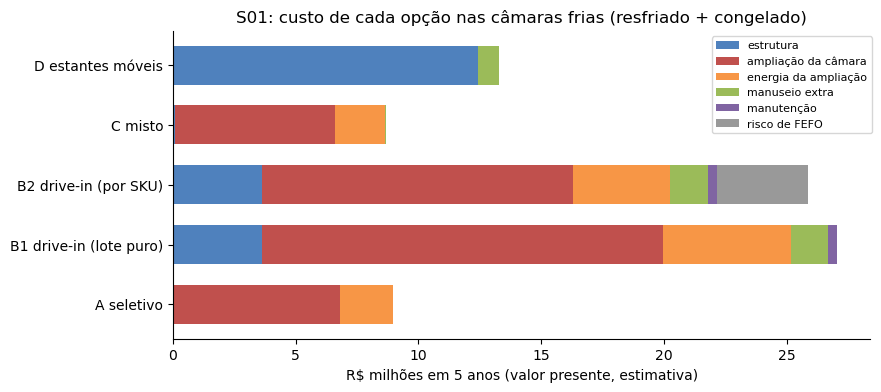

In [6]:
# Barras empilhadas: composição do custo de 5 anos de cada opção (onde está o dinheiro em cada escolha).
fig, ax = plt.subplots(figsize=(9, 4))
(tot[cols] / 1e6).plot.barh(stacked=True, ax=ax, width=0.65,
                            color=["#4F81BD", "#C0504D", "#F79646", "#9BBB59", "#8064A2", "#999999"])
ax.set_xlabel("R$ milhões em 5 anos (valor presente, estimativa)"); ax.set_ylabel("")
ax.legend(["estrutura", "ampliação da câmara", "energia da ampliação", "manuseio extra", "manutenção",
           "risco de FEFO"], fontsize=8, bbox_to_anchor=(1.01, 1))
ax.set_title("S01: custo de cada opção nas câmaras frias (resfriado + congelado)")
savefig(fig, "08c_s01_custos", out=PH8)

### Pontos de equilíbrio: quando as estantes móveis passam a valer a pena?
As duas premissas que mais pesam são o preço da estante móvel por posição e o custo de construir
câmara nova. Calculamos o valor de cada uma que **empata** D com A + ampliação.

In [7]:
A_, D_ = tot.loc["A seletivo"], tot.loc["D estantes móveis"]
pos_D = sum(POS[z] * (1 + S["mobile_density_gain"]) for z in FRIO)
preco_empate = (A_.custo_total_vp - D_.manuseio_extra_vp) / pos_D
fator_obra = (D_.custo_total_vp - A_.energia_ampliacao_vp) / A_.capex_ampliacao
obra_empate = S["cold_chamber_build_brl_m2"] * fator_obra
equil = pd.DataFrame({
    "premissa": ["preço da estante móvel (R$/posição)", "custo de construir câmara (R$/m²)"],
    "valor_usado": [precos["mobile"], S["cold_chamber_build_brl_m2"]],
    "valor_de_empate": [preco_empate, obra_empate]})
save(equil.round(0), "08c_s01_equilibrio", out=PH8)
equil.round(0)

,premissa,valor_usado,valor_de_empate
0,preço da estante móvel (R$/posição),1600,1044.0
1,custo de construir câmara (R$/m²),4500,7356.0


## 5. Quadro de decisão para a diretoria
| Critério | A Seletivo | B Drive-in | C Misto | D Estantes móveis |
|---|---|---|---|---|
| Capacidade útil | base | **menor** que A respeitando FEFO; maior só misturando lotes | ≈ A (poucos lotes enchem pista) | **+80%** |
| FEFO / bloqueio de lote | pleno | **comprometido** se misturar lotes | pleno | pleno |
| Produtividade | base | −40% por movimento | ≈ A | −1 min por movimento |
| Pico atual (110–115%) | transborda | transborda (B1) | transborda | **resolve** |
| Crescimento em 5 anos | exige ampliar a câmara | exige ampliar | exige ampliar | absorve |
| Custo em 5 anos (VP) | ver tabela | ver tabela | ver tabela | ver tabela |

**Recomendação da análise:**
1. **Descartar o drive-in (B):** o SDC tem muitos SKUs com poucos paletes e ~2 lotes cada. Respeitando o
   FEFO, só ~28% de cada pista é usado e a capacidade útil **cai para menos da metade** do seletivo atual.
   Misturando lotes, 74–86% dos paletes ficariam presos atrás de outro lote. Custaria R$ 17–18 mi a mais
   em 5 anos.
2. **O misto (C) empata com o seletivo:** só 2–3% dos paletes enchem uma pista; a diferença (R$ 0,3 mi)
   fica dentro da incerteza e não paga a complexidade da regra de alocação.
3. A escolha real é **A seletivo + ampliação da câmara × D estantes móveis**:
   - com as premissas atuais, **A + ampliação sai mais barato** (≈ R$ 9 mi × R$ 13 mi em 5 anos);
   - mas a ampliação é **obra**: até ficar pronta, o pico continua transbordando (110–115%). A opção D
     resolve o transbordo **já** e absorve 5 anos de crescimento;
   - **D passa a valer a pena** se a estante móvel custar até o valor de empate por posição, ou se a obra
     de câmara custar acima do valor de empate por m² (tabela de equilíbrio).
4. **Próximo passo:** pedir orçamentos reais de estante móvel e de ampliação, e então decidir. Enquanto
   isso, aliviar o pico com as ações sem CAPEX (slotting, estoque de segurança por SKU, liquidação de parados).

A decisão é da diretoria. Este é o trade-off quantificado.

In [8]:
melhor = tot.custo_total_vp.idxmin()
print(f"Opção de menor custo em 5 anos (VP): {melhor} — R$ {tot.loc[melhor, 'custo_total_vp'] / 1e6:,.1f} mi "
      f"(A seletivo + ampliação: R$ {tot.loc['A seletivo', 'custo_total_vp'] / 1e6:,.1f} mi)")
log(NB, f"S01: perfil lote/SKU nas câmaras (24 meses); pistas de {D} paletes; capacidade útil por opção; "
        f"necessidade = pico x 1,05^{ANOS}; custo VP {ANOS} anos a {taxa:.0%}")

Opção de menor custo em 5 anos (VP): C misto — R$ 8.7 mi (A seletivo + ampliação: R$ 9.0 mi)
